# Solving Durablemodel with Taste shocks in infinite horizon

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
from pathlib import Path

start_time = time.time()

from DurableModel import DurableConsumer
from HARK.ConsumptionSaving.ConsIndShockModel import utility_inv

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.3,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=5.0,
    nNrmCount=100,
    mNrmMax=8.0,
    mNrmCount=100,
    xNrmMax=13.0,
    xNrmCount=200,
    aNrmMax=8.0,
    aNrmCount=100,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-6,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=300,  # iteration cap for cycles=0 (matches background max_cycles)
    distance_metric="mse",
    verbose=False,
)


In [3]:
base_taste = copy.deepcopy(durable_defaults)
base_taste["sigma_eps"] = 0.05
base_taste["PriceShkStd"] = 0.0
base_taste["PriceShkCount"] = 1
base_taste["SearchCost"] = 0.0
base_taste["cycle"] = 0
base_taste["TranMatrixmCount"] = 250
base_taste["diagnostics"] = False     # in your notebook config

taste_model = DurableConsumer(**base_taste)
taste_model.update()
taste_model.solve()

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:544: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:551: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:184: RuntimeWarning: divide by zero encountered in power
  return uP ** (-1.0 / rho)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - r

1000.0
0.2315070657076427
0.06134697256738687
0.02482571335596517
0.012565954026755557
0.007155876377598205
0.004541374632814087
0.005057207909447988
0.0039769126198770785
0.004445832299141973
0.004294401066137818
0.004820534966290519


c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\utility.py:552: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (


0.0046726402455492646
0.004628531071219519
0.007590595636222677
0.008203389720081649
0.006500954011128291
0.0033546453470212553
0.0053704194214519016
0.15634900769705884
0.08610534938602699
0.12535629655111552


c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:1210: RuntimeWarning: invalid value encountered in subtract
  return self.CRRAutilityPD(c, d) - price * eop1 + eopd


0.1411339072294043
0.14660057585241248
0.14944155507226314
0.14242648767678837
0.13278655750387647
0.1238002849782708
0.13445088413383632
0.12485781938405259
0.10971164141375037
0.0903812129912167
0.09665736292638721
0.06995284763859841
0.07369984388838415
0.05995500795721321
0.05321019321619014
0.046268504320075204
0.04336710004611995
0.039405153906091485
0.0358309829106697
0.03277318770677194
0.02984736513804312
0.026844137197059748
0.02364663393827807
0.02021786426260061
0.016641790965878818
0.013231589651441115
0.010309362159593206
0.007250289167415245
0.00411153312963148
0.0024259147193061077
0.0014266423495732578
0.0012132605194034513
0.0013266343296057539
0.001507821711653297
0.0016249337334599619
0.0016011096384439365
0.0013327205282816022
0.0008683902951143771
0.00046139170566098246
0.00021094400178620562
9.429133823483453e-05
4.760562140465239e-05
2.7681556876873656e-05
1.744520525283269e-05
1.1393878354962905e-05
7.833858977089208e-06
6.46557736082056e-06
7.897483384403682e-

In [5]:
taste_model.compute_steady_state()

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\scipy\sparse\_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


(0.053619038398653764,
 0.9638760994597554,
 0.33087003788936953,
 0.016543501894468494,
 0.9804196013542239,
 0.23172897906541548)

In [6]:
print("Steady-state aggregates:")
print(f"  Consumption SS (C):        {taste_model.C_ss:.6f}")
print(f"  Durable stock SS (D):      {taste_model.D_ss:.6f}")
print(f"  Durable expenditure (DEX): {taste_model.DEX_ss:.6f}")
print(f"  Total expenditure (TEX):   {taste_model.TEX_ss:.6f}")
print(f"  Assets SS (A):             {taste_model.A_ss:.6f}")
print(f"  Adjustment share (ADJ):    {taste_model.ADJ_ss:.6f}")

Steady-state aggregates:
  Consumption SS (C):        0.963876
  Durable stock SS (D):      0.330870
  Durable expenditure (DEX): 0.016544
  Total expenditure (TEX):   0.980420
  Assets SS (A):             0.053619
  Adjustment share (ADJ):    0.231729


In [7]:
import matplotlib.pyplot as plt

T = 50
J_C, J_DEX, J_TEX, J_D, J_A, J_ADJ = taste_model.calc_jacobian("Rfree", T)

jacobians = {
    "C": J_C,
    "DEX": J_DEX,
    "TEX": J_TEX,
    "D": J_D,
    "A": J_A,
    "ADJ": J_ADJ,
}


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:551: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel.py:544: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:184: RuntimeWarning: divide by zero encountered in power
  return uP ** (-1.0 / rho)


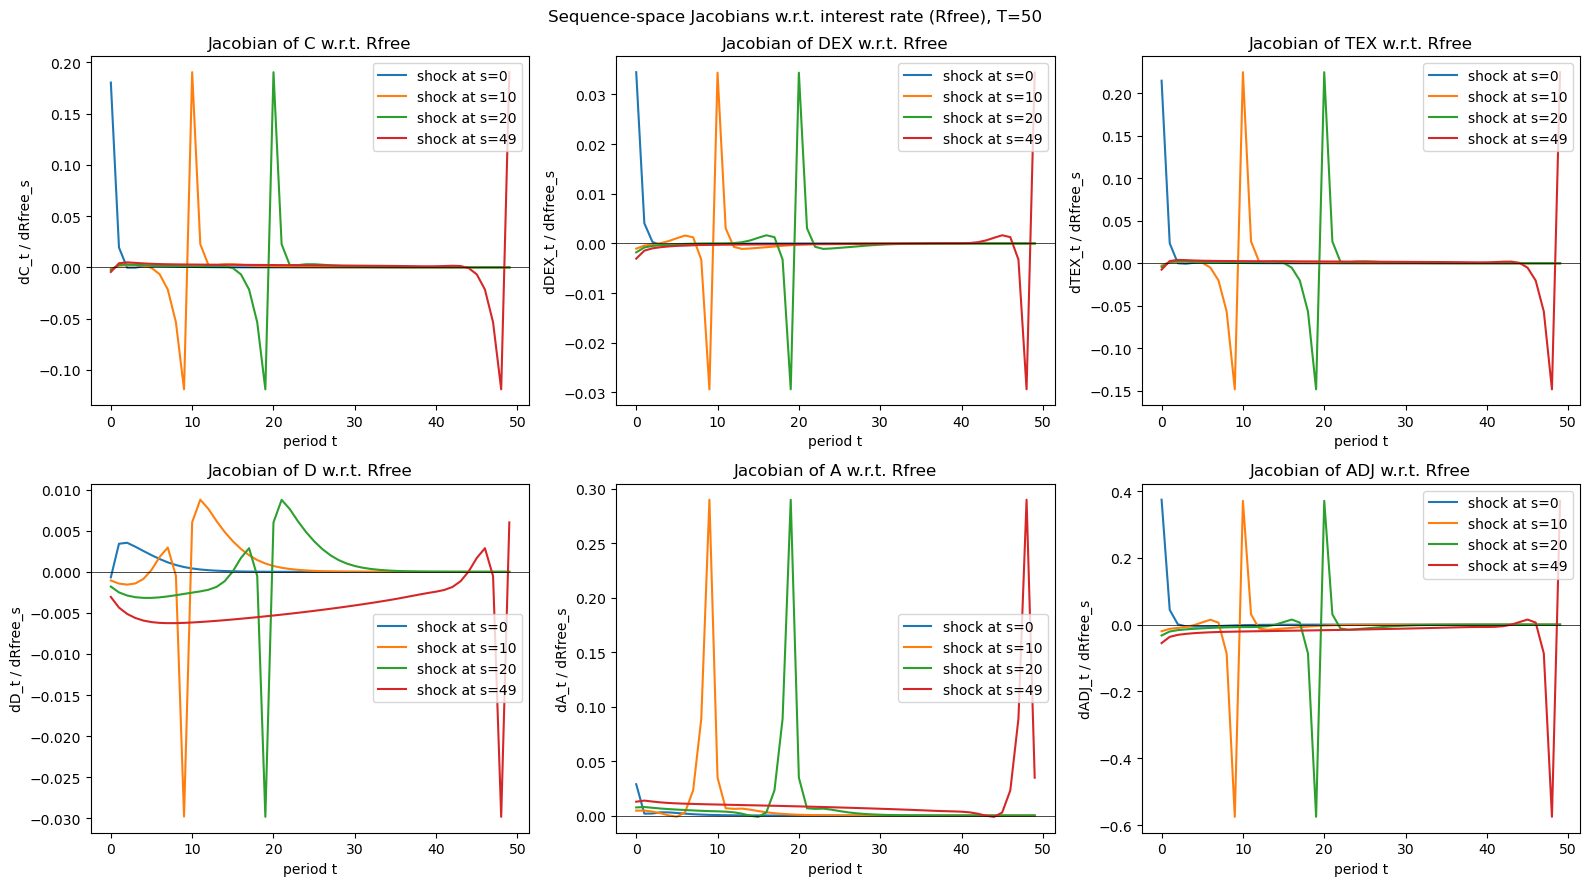

In [8]:
cols = [0, 10, 20, 49]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, J) in zip(axes.flat, jacobians.items()):
    for s in cols:
        ax.plot(J[:, s], label=f"shock at s={s}")
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. Rfree")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dRfree_s")
    ax.legend()
fig.suptitle("Sequence-space Jacobians w.r.t. interest rate (Rfree), T=50")
fig.tight_layout()
plt.show()